# Real-data validation: Hodge decomposition on a human breast Visium slice (TENX53)

**Project:** Hodge-Aware Topological Deep Learning for Cell-Cell Communication (PW_27_CN_08)  |  **Author:** Dhriti (P3, Hodge core)

The synthetic notebook showed the decomposition is correct on toy tissue. Here everything is built from **real data**: the real spot positions and real gene expression of slice TENX53 (from HEST, shared by Mayur).

What is real and what is a stand-in:

| Part | Real? |
|---|---|
| Mesh (spots, edges, triangles, holes) | Real: built from the slice's spot lattice |
| Topology check (holes) | Real |
| Planted-flow recovery | Planted flows on the **real mesh** (so the right answer is known) |
| Ligand-receptor flows | **Proxy** computed directly from expression, until Disha's LIANA+/COMMOT flows replace them |

In [1]:
import os, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import anndata as ad
import gudhi

from hodgecc.visium import build_visium_complex, enclosed_gaps
from hodgecc.hodge import decompose, energy_fractions

for cand in ["../data/starter.h5ad", "data/starter.h5ad"]:
    if os.path.exists(cand):
        PATH = cand
        break
else:
    raise FileNotFoundError("put starter.h5ad in the repo's data/ folder")

adata = ad.read_h5ad(PATH)
adata = adata[adata.obs["in_tissue"] == 1].copy()
sample = str(adata.obs["sample_id"].iloc[0])
r, c = adata.obs["array_row"].values, adata.obs["array_col"].values
edges, tris, B1, B2 = build_visium_complex(r, c)
N, E = B1.shape
T = B2.shape[1]
print(f"{sample}: {N} spots, {adata.n_vars} genes")

TENX53: 4869 spots, 21349 genes


## A. The real mesh

Every spot is a node; neighbouring spots on the Visium hexagonal lattice are joined by an edge; each triple of mutually adjacent spots is a filled triangle. Red crosses mark **missing spots inside the tissue**, which show up as holes in the mesh.

spots               4869
edges              14289
triangles           9413
components (b0)        1
holes (b1)             8
Euler N-E+T           -7
missing spots per hole: [7, 2, 1, 1, 1, 1, 1, 1]


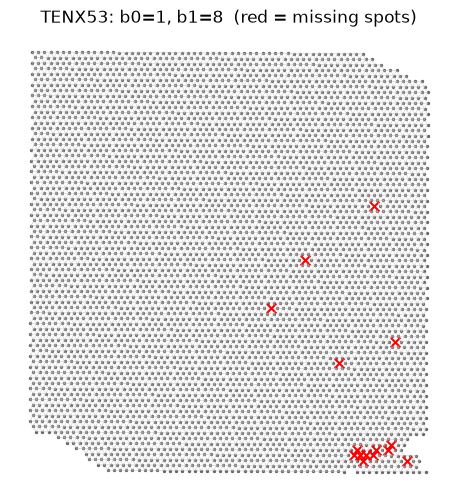

In [2]:
st = gudhi.SimplexTree()
for i in range(N): st.insert([i])
for e in edges: st.insert([int(e[0]), int(e[1])])
for t in tris: st.insert([int(x) for x in t])
st.compute_persistence()
b0, b1 = st.betti_numbers()[:2]
gaps = enclosed_gaps(r, c)

print(pd.Series({"spots": N, "edges": E, "triangles": T,
                 "components (b0)": b0, "holes (b1)": b1,
                 "Euler N-E+T": N - E + T}).to_string())
print("missing spots per hole:", [len(g) for g in gaps])

xy = np.asarray(adata.obsm["spatial"], float)
coef, *_ = np.linalg.lstsq(np.column_stack([c, r, np.ones(N)]), xy, rcond=None)
fig, ax = plt.subplots(figsize=(7, 6))
seg = np.stack([xy[edges[:, 0]], xy[edges[:, 1]]], axis=1)
ax.add_collection(LineCollection(seg, colors="0.75", linewidths=0.3))
ax.scatter(xy[:, 0], xy[:, 1], s=2, color="0.4")
for g in gaps:
    pts = np.array([[cc, rr, 1.0] for rr, cc in g]) @ coef
    ax.scatter(pts[:, 0], pts[:, 1], s=50, color="red", marker="x")
ax.invert_yaxis(); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"{sample}: b0={b0}, b1={b1}  (red = missing spots)")
plt.show()

**Reading it.** The mesh is one connected piece (b0 = 1) with 8 holes, and `N - E + T = b0 - b1` holds, which is an independent consistency check. Every hole is a gap of missing spots (six single spots, one gap of 2, one of 7). The tissue fills almost the whole capture area, so these are dropped spots rather than glands or vessels.

## B. Counting holes a second way (spectrum of the Hodge Laplacian)

The number of holes also equals the number of zero eigenvalues of the Hodge Laplacian `L1 = B1^T B1 + B2 B2^T`. This is independent of the gudhi count above, and it also gives us the 8 harmonic flows themselves.

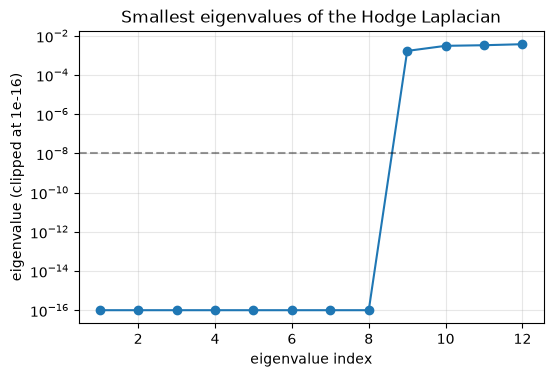

near-zero eigenvalues: 8 | next eigenvalue: 1.70e-03


In [3]:
L1 = (B1.T @ B1 + B2 @ B2.T).tocsc()
vals, vecs = eigsh(L1, k=12, sigma=-0.01, which="LM")
order = np.argsort(vals)
vals, vecs = vals[order], vecs[:, order]
n_zero = int((vals < 1e-8).sum())
V = vecs[:, :n_zero]                      # basis of the harmonic space

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.semilogy(np.arange(1, 13), np.maximum(vals, 1e-16), "o-")
ax.axhline(1e-8, color="k", ls="--", alpha=0.4)
ax.set_xlabel("eigenvalue index"); ax.set_ylabel("eigenvalue (clipped at 1e-16)")
ax.set_title("Smallest eigenvalues of the Hodge Laplacian"); ax.grid(alpha=0.3)
plt.show()
print("near-zero eigenvalues:", n_zero, "| next eigenvalue:", f"{vals[n_zero]:.2e}")

**Reading it.** There are exactly 8 eigenvalues at numerical zero, then a clear jump. So the spectrum also says 8 holes, in agreement with gudhi.

## C. Planted flows on the real mesh

Same test as the synthetic notebook, but on the real mesh with its real irregularities: plant a known gradient, curl and harmonic flow with equal energy, decompose, and measure the error. The harmonic flow is built from the 8 zero-eigenvalue vectors above, so it is independent of the decomposition code.

In [4]:
def rel(a, b): return np.linalg.norm(a - b) / np.linalg.norm(b)

def planted(seed):
    rng = np.random.default_rng(seed)
    g = B1.T @ rng.normal(size=N)
    cu = B2 @ rng.normal(size=T)
    h = V @ rng.normal(size=V.shape[1])
    parts = [x / np.linalg.norm(x) for x in (g, cu, h)]
    return sum(parts), parts

rows = []
for snr in [np.inf, 100, 10, 3, 1]:
    acc = []
    for seed in range(5):
        f, parts = planted(seed)
        if np.isfinite(snr):
            n = np.random.default_rng(100 + seed).normal(size=f.shape)
            f = f + n * np.linalg.norm(f) / snr / np.linalg.norm(n)
        gg, cc, hh = decompose(B1, B2, f)
        acc.append([rel(gg, parts[0]), rel(cc, parts[1]), rel(hh, parts[2])])
    rows.append(np.mean(acc, axis=0))
tab = pd.DataFrame(rows, columns=["gradient", "curl", "harmonic"],
                   index=pd.Index(["no noise", "100", "10", "3", "1"], name="SNR"))
tab.style.format("{:.2e}")

,gradient,curl,harmonic
SNR,,,
no noise,6.82e-11,1.04e-10,1.25e-10
100,1.01e-02,1.41e-02,3.85e-04
10,1.01e-01,1.41e-01,3.85e-03
3,3.36e-01,4.69e-01,1.28e-02
1,1.01e+00,1.41e+00,3.85e-02


**Reading it.** Without noise the three parts are recovered to numerical precision on the real mesh. With noise, the gradient and curl errors grow with the noise, while the harmonic part stays far more accurate, just as on the toy mesh. Here the harmonic space is only 8-dimensional out of 14,289 edge directions, so it catches very little noise.

## D. Ligand-receptor flows from real expression, with a shuffled control

We need one number per edge saying how much signal flows from spot *i* to spot *j*. As a **proxy** (to be replaced by Disha's LIANA+/COMMOT flows), for a ligand L and receptor R on edge (i, j) with i < j:

`flow = L[i] * R[j]  -  L[j] * R[i]`

Positive means spot i sends to spot j (ligand at i, receptor at j). We use 8 well-known pairs.

**Control.** Shuffle which spot each (L, R) expression pair belongs to. Every spot keeps its values, but the spatial arrangement is destroyed. If the real flows decompose differently from shuffled ones, the decomposition is responding to spatial structure and not just to the amount of expression. We use 20 shuffles.

In [5]:
pairs = [("CXCL12","CXCR4"), ("TGFB1","TGFBR2"), ("VEGFA","KDR"), ("PDGFB","PDGFRB"),
         ("CCL19","CCR7"), ("CXCL9","CXCR3"), ("MIF","CD74"), ("SPP1","CD44")]
X = adata.X.tocsc() if sp.issparse(adata.X) else adata.X
def col(gene):
    j = adata.var_names.get_loc(gene)
    return X[:, j].toarray().ravel() if sp.issparse(X) else np.asarray(X[:, j]).ravel()
L = np.column_stack([col(l) for l, _ in pairs])
R = np.column_stack([col(rr) for _, rr in pairs])
ei, ej = edges[:, 0], edges[:, 1]
def flows(L, R): return L[ei] * R[ej] - L[ej] * R[ei]       # (E, C), i -> j positive

F = flows(L, R)
real = energy_fractions(*decompose(B1, B2, F))                # (3, C)

rng = np.random.default_rng(0)
shuf = np.array([energy_fractions(*decompose(B1, B2, flows(L[p], R[p])))
                 for p in (rng.permutation(N) for _ in range(20))])   # (20, 3, C)

rows = []
for k, (l, rr) in enumerate(pairs):
    rows.append({
        "pair": f"{l}-{rr}",
        "gradient % real": 100 * real[0, k],
        "gradient % shuffled": 100 * shuf[:, 0, k].mean(),
        "curl % real": 100 * real[1, k],
        "curl % shuffled": 100 * shuf[:, 1, k].mean(),
        "harmonic % real": 100 * real[2, k],
        "harmonic % shuffled": 100 * shuf[:, 2, k].mean(),
        "gradient above all shuffles": bool(real[0, k] > shuf[:, 0, k].max()),
    })
res = pd.DataFrame(rows).set_index("pair")
res.style.format({c_: "{:.2f}" for c_ in res.columns[:4]} |
                 {c_: "{:.3f}" for c_ in res.columns[4:6]})

,gradient % real,gradient % shuffled,curl % real,curl % shuffled,harmonic % real,harmonic % shuffled,gradient above all shuffles
pair,,,,,,,
CXCL12-CXCR4,67.64,57.22,32.28,42.74,0.082,0.036,True
TGFB1-TGFBR2,64.34,55.77,35.65,44.20,0.011,0.038,True
VEGFA-KDR,63.67,58.83,36.32,41.15,0.008,0.026,True
PDGFB-PDGFRB,63.04,58.68,36.95,41.28,0.010,0.042,True
CCL19-CCR7,81.37,50.68,18.63,49.26,0.008,0.061,True
CXCL9-CXCR3,67.48,50.13,32.49,49.81,0.032,0.060,True
MIF-CD74,99.13,99.37,0.78,0.63,0.085,0.000,False
SPP1-CD44,83.51,76.52,16.47,23.46,0.027,0.025,True


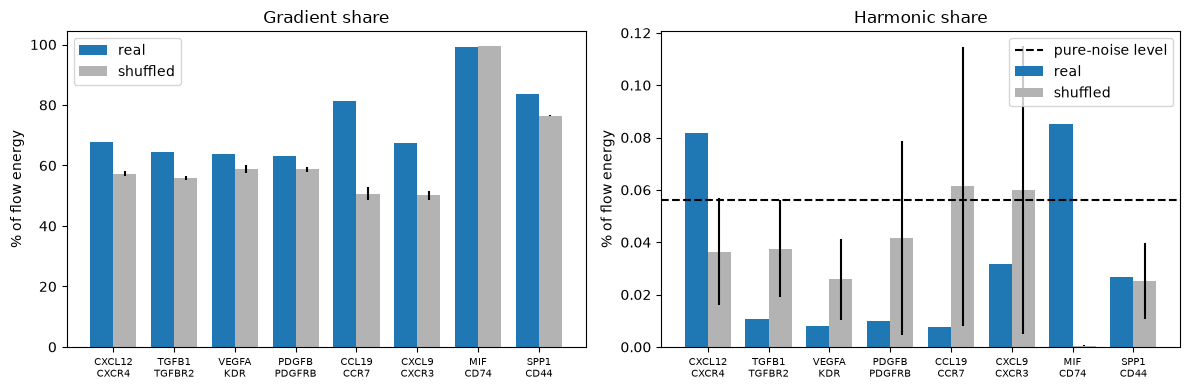

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(pairs)); w = 0.38
names = [f"{l}\n{rr}" for l, rr in pairs]
axs[0].bar(x - w/2, 100 * real[0], w, label="real")
axs[0].bar(x + w/2, 100 * shuf[:, 0].mean(0), w,
           yerr=100 * shuf[:, 0].std(0), label="shuffled", color="0.7")
axs[0].set_xticks(x); axs[0].set_xticklabels(names, fontsize=7)
axs[0].set_ylabel("% of flow energy"); axs[0].set_title("Gradient share"); axs[0].legend()
axs[1].bar(x - w/2, 100 * real[2], w, label="real")
axs[1].bar(x + w/2, 100 * shuf[:, 2].mean(0), w,
           yerr=100 * shuf[:, 2].std(0), label="shuffled", color="0.7")
axs[1].axhline(100 * V.shape[1] / E, color="k", ls="--", label="pure-noise level")
axs[1].set_xticks(x); axs[1].set_xticklabels(names, fontsize=7)
axs[1].set_ylabel("% of flow energy"); axs[1].set_title("Harmonic share"); axs[1].legend()
plt.tight_layout(); plt.show()

**Reading it.**

- **Gradient / curl.** For most pairs the real flows have a *larger gradient share and a smaller curl share* than the shuffled ones, so the decomposition responds to the spatial arrangement of expression. MIF-CD74 is already almost entirely gradient because both genes are expressed nearly everywhere.
- **Harmonic.** The harmonic share is tiny for every pair (well under 0.1% of the energy), close to the level expected from pure noise (dashed line). That is expected on this slice: its only 8 holes are missing spots, so there are no real gland- or vessel-like structures for loops to circulate around. CXCL12-CXCR4 and MIF-CD74 sit slightly above their shuffled levels, but at under 0.1% of the energy this is not a meaningful loop signal.

**Caution.** The flow here is a simple expression product, and higher gradient share can come from spatially smooth expression alone. This shows the pipeline runs end to end on real data and separates real from shuffled; it is not evidence of real signalling circuits yet.

## Summary and next steps

| Check | Result on TENX53 |
|---|---|
| Mesh | 4,869 spots, 14,289 edges, 9,413 triangles, one connected piece |
| Holes | 8 by gudhi and 8 by the Hodge Laplacian spectrum; all are missing spots |
| Planted flows on the real mesh | Recovered to numerical precision; harmonic part most noise-robust |
| Real vs shuffled (proxy L-R flows) | Real flows differ from shuffled in gradient/curl share; harmonic share is negligible here |

**Next:** (1) replace `F` with Disha's LIANA+/COMMOT flows (same shape `(14289, C)`, same edge order); (2) repeat on a tissue with real glands or vessels, where harmonic flow can matter; (3) apply a gap-size rule (fill gaps of 1-2 spots) before treating holes as biology.